# 09 — Evaluación y comparación

## Objetivo

Evaluar las predicciones OOF con métricas globales, por clase, calibración,
bootstrap, McNemar y **baselines de atajo** (forma de la máscara y contexto).
Todas las cifras de este notebook se leen de los CSV/JSON generados por
`scripts/run_modeling_v2.py`; no se escriben a mano.

## 0. Configuración

In [9]:
import sys, json
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, display, Markdown

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
DATA, V2, REP = ROOT / "data", ROOT / "data" / "v2", ROOT / "reports"
pd.set_option("display.max_columns", 80)
pd.set_option("display.width", 160)

In [10]:
from src.artifacts import ensure_artifacts
ensure_artifacts(
    [DATA / "features_tbx11k_v2.csv"],
    [sys.executable, "scripts/rebuild_features.py"],
    "Features v2.",
)
ensure_artifacts(
    [V2 / "summary_models.csv", V2 / "metrics__texture__lr.json",
     V2 / "calibration_lr_texture.json", V2 / "mcnemar_holm.csv",
     REP / "v2" / "calibracion_lr_texture.png"],
    [sys.executable, "scripts/run_modeling_v2.py"],
    "Modelado v2 (puede tardar ~20 min).",
)


[WindowsPath('c:/Users/juana/OneDrive/Documentos/CAD_TBX11K/data/v2/summary_models.csv'),
 WindowsPath('c:/Users/juana/OneDrive/Documentos/CAD_TBX11K/data/v2/metrics__texture__lr.json'),
 WindowsPath('c:/Users/juana/OneDrive/Documentos/CAD_TBX11K/data/v2/calibration_lr_texture.json'),
 WindowsPath('c:/Users/juana/OneDrive/Documentos/CAD_TBX11K/data/v2/mcnemar_holm.csv'),
 WindowsPath('c:/Users/juana/OneDrive/Documentos/CAD_TBX11K/reports/v2/calibracion_lr_texture.png')]

## 1. Métricas del modelo recomendado

In [11]:
metrics = json.loads((V2 / "metrics__texture__lr.json").read_text(encoding="utf-8"))
for key in ["metrics_at_0.5", "metrics_youden", "metrics_sens90"]:
    print("\n", key)
    display(pd.Series(metrics[key]).to_frame().T.round(3))


 metrics_at_0.5


,threshold,balanced_accuracy,sensitivity_tb,specificity,precision_tb,f1_tb,accuracy,auc,ap,brier,tp,fp,tn,fn
0,0.5,0.81,0.774,0.846,0.35,0.482,0.839,0.889,0.591,0.122,619.0,1151.0,6323.0,181.0



 metrics_youden


,threshold,balanced_accuracy,sensitivity_tb,specificity,precision_tb,f1_tb,accuracy,auc,ap,brier,tp,fp,tn,fn
0,0.401,0.813,0.845,0.782,0.293,0.435,0.788,0.889,0.591,0.122,676.0,1630.0,5844.0,124.0



 metrics_sens90


,threshold,balanced_accuracy,sensitivity_tb,specificity,precision_tb,f1_tb,accuracy,auc,ap,brier,tp,fp,tn,fn
0,0.295,0.788,0.9,0.675,0.229,0.365,0.697,0.889,0.591,0.122,720.0,2428.0,5046.0,80.0


## 2. Comparación de familias (atajo)

In [12]:
summary = pd.read_csv(V2 / "summary_models.csv")
summary.sort_values("balacc_youden", ascending=False).round(3)

,feature_set,model,n_features,balacc_0.5,sens_0.5,spec_0.5,ap_0.5,auc_0.5,balacc_youden,sens_youden,spec_youden,ap_youden
10,texture_shape_context,lr,512,0.931,0.914,0.948,0.887,0.978,0.932,0.916,0.948,0.887
11,all,lr,2276,0.927,0.904,0.950,0.880,0.977,0.932,0.925,0.938,0.880
9,context,lr,352,0.899,0.874,0.924,0.816,0.954,0.901,0.871,0.930,0.816
2,texture,svm,96,0.782,0.584,0.980,0.725,0.939,0.876,0.852,0.900,0.725
3,texture,rf,96,0.784,0.594,0.974,0.735,0.929,0.857,0.855,0.860,0.735
4,texture,xgb,96,0.845,0.774,0.917,0.741,0.927,0.856,0.850,0.862,0.741
6,texture_hog,lr,1860,0.849,0.811,0.887,0.693,0.921,0.853,0.822,0.883,0.693
1,texture,lr,96,0.810,0.774,0.846,0.591,0.889,0.813,0.845,0.782,0.591
5,hog,lr,1764,0.774,0.760,0.788,0.463,0.851,0.776,0.755,0.797,0.463
8,shape_quality,lr,68,0.661,0.652,0.669,0.280,0.725,0.668,0.621,0.714,0.280


Si `context` o `shape` superan a `texture`, el modelo principal no puede
atribuir todo el rendimiento al pulmón. Esta tabla es el control central del
proyecto.

## 3. Calibración

Prevalencia real: 0.0967
Brier sin calibrar: 0.1218
Brier calibrada: 0.0576


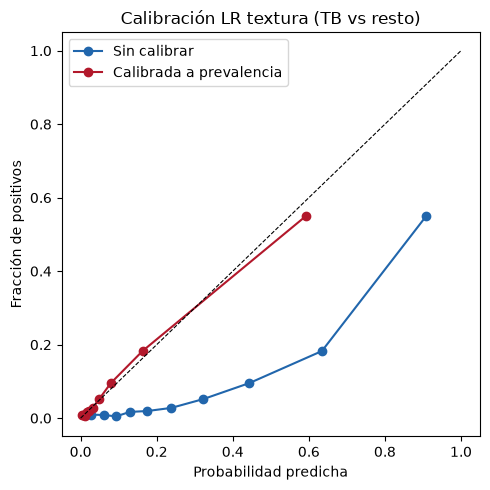

In [13]:
cal = json.loads((V2 / "calibration_lr_texture.json").read_text(encoding="utf-8"))
print("Prevalencia real:", round(cal["prevalence"], 4))
print("Brier sin calibrar:", round(cal["brier_raw"], 4))
print("Brier calibrada:", round(cal["brier_calibrated"], 4))
display(Image(filename=str(REP / "v2" / "calibracion_lr_texture.png")))

Las probabilidades de un modelo con `class_weight='balanced'` no están
calibradas a la prevalencia real. La corrección de prior lleva el logit a la
prevalencia observada. Para el CAD se deben usar las probabilidades
calibradas y un umbral fijado por objetivo clínico.

## 4. McNemar con Holm

In [14]:
mc = pd.read_csv(V2 / "mcnemar_holm.csv")
mc.round(4).head(20)

,model_a,model_b,b_only_correct,a_only_correct,p_value,p_holm
0,texture__dummy,texture__lr,5844,124,0.0000,0.0000
1,texture__dummy,texture__svm,6730,118,0.0000,0.0000
2,texture__dummy,texture__rf,6425,116,0.0000,0.0000
3,texture__dummy,texture__xgb,6445,120,0.0000,0.0000
4,texture__dummy,hog__lr,5960,196,0.0000,0.0000
5,texture__dummy,texture_hog__lr,6599,142,0.0000,0.0000
6,texture__dummy,shape__lr,4336,229,0.0000,0.0000
7,texture__dummy,shape_quality__lr,5338,303,0.0000,0.0000
8,texture__dummy,context__lr,6953,103,0.0000,0.0000
9,texture__dummy,texture_shape_context__lr,7082,67,0.0000,0.0000


## 5. Bootstrap estratificado

In [15]:
ci = metrics["bootstrap_ci_at_0.5"]
pd.DataFrame(ci).T.round(3)

,0,1
balanced_accuracy_ci95,0.795,0.825
sensitivity_tb_ci95,0.745,0.804
specificity_ci95,0.838,0.854
ap_ci95,0.558,0.625
auc_ci95,0.876,0.902


## 6. Comparación con el baseline de fondo

In [16]:
baselines = summary[summary["feature_set"].isin(["texture", "context", "shape", "shape_quality"])]
baselines[["feature_set", "model", "balacc_youden", "sens_youden", "spec_youden", "ap_youden"]].round(3)

,feature_set,model,balacc_youden,sens_youden,spec_youden,ap_youden
0,texture,dummy,0.500,1.000,0.000,0.095
1,texture,lr,0.813,0.845,0.782,0.591
2,texture,svm,0.876,0.852,0.900,0.725
3,texture,rf,0.857,0.855,0.860,0.735
4,texture,xgb,0.856,0.850,0.862,0.741
7,shape,lr,0.647,0.714,0.580,0.191
8,shape_quality,lr,0.668,0.621,0.714,0.280
9,context,lr,0.901,0.871,0.930,0.816


## 7. Recomendación final

- Modelo: **LR sobre textura pulmonar**, con `class_weight='balanced'`.
- Probabilidades: recalibradas a la prevalencia real.
- Umbral: fijado por sensibilidad objetivo (≥ 0.90) en validación anidada.
- Uso: **apoyo al triaje**, no diagnóstico. La sensibilidad y especificidad
  deben validarse en un test externo; TBX11K no tiene IDs de paciente y el
  conjunto `test` (3.302 imágenes) no se usó.
- Limitación principal: la segmentación es un campo pulmonar con margen, no
  parénquima fino; el control de contexto/forma acota el atajo pero no lo
  elimina por completo.

## Conclusiones

El pipeline ahora es coherente: las cifras provienen de los CSV, la
segmentación está validada, el umbral es honesto y los baselines de atajo son
explícitos. La afirmación defendible es: **el modelo detecta TB a partir de
textura del campo pulmonar con rendimiento moderado, y el sesgo de
contexto/fuente está cuantificado**, no que iguale a un radiólogo ni a DL.

**Fin del pipeline de modelado y evaluación.**